In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import math
import matplotlib.pyplot as plt

In [ ]:
from pathlib import Path
import sys
sys.path.append(str(Path.cwd().parent))
from config import SEED
path = Path.cwd().parents[1]/ "data" / "real_data"



In [3]:
FEATURES = ["lepton_1_pT", "lepton_1_eta", "lepton_1_phi", "lepton_2_pT", "lepton_2_eta", "lepton_2_phi", "missing_energy_magnitude", "missing_energy_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos(theta_r1)"]
df = pd.read_parquet(path / "binary" / "susy.parquet")
df = df.rename(columns={f"f{i}": c for i, c in enumerate(FEATURES)} | {"target": "class"})
df = df[["class"] + FEATURES].astype({"class": "bool"})
df = df.sample(frac=0.2, random_state=SEED).reset_index(drop=True)

In [4]:
df.head()

,class,lepton_1_pT,lepton_1_eta,lepton_1_phi,lepton_2_pT,lepton_2_eta,lepton_2_phi,missing_energy_magnitude,missing_energy_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos(theta_r1)
0,False,0.720287,-0.017012,-0.608006,0.875663,-0.631706,0.710822,0.909933,-1.687186,1.365922,-0.537207,0.693668,0.989813,1.266248,1.582939,0.751710,1.254138,1.371600,0.112120
1,False,0.849947,-1.254984,-0.098452,1.117716,-0.375948,1.051920,0.519807,-1.376361,0.780295,-0.205800,0.898913,0.869035,0.857899,1.533020,0.879287,1.159261,0.034953,0.095634
2,True,2.433653,0.689772,-1.688011,0.764698,0.504335,-0.499661,0.240126,0.804055,0.332966,0.226203,1.515174,0.751718,0.440261,1.103019,1.122941,0.997454,0.126183,0.427268
3,True,1.408545,-0.444139,1.721950,2.189539,-0.943634,0.137413,1.733998,1.424760,1.008567,1.751768,1.485510,1.621332,0.968528,0.000000,1.531114,0.752177,1.467619,0.219470
4,False,0.479241,1.512133,-0.053951,0.540713,0.490473,0.709906,0.289003,1.420305,0.415076,0.162520,0.494121,0.455021,0.817172,0.760130,0.430422,0.660266,0.455098,0.227519


In [17]:
print(df.shape)
print(df["class"].value_counts())
print(df.describe().T)

(1000000, 19)
class
False    542259
True     457741
Name: count, dtype: int64
                              count       mean    std        min    25%  \
lepton_1_pT               1000000.0  1.000e+00  0.687  2.549e-01  0.562   
lepton_1_eta              1000000.0  1.062e-03  1.003 -2.103e+00 -0.755   
lepton_1_phi              1000000.0 -3.902e-04  1.001 -1.735e+00 -0.867   
lepton_2_pT               1000000.0  9.993e-01  0.652  4.286e-01  0.597   
lepton_2_eta              1000000.0  1.270e-03  1.004 -2.059e+00 -0.769   
lepton_2_phi              1000000.0 -1.523e-03  1.002 -1.734e+00 -0.872   
missing_energy_magnitude  1000000.0  1.000e+00  0.875  7.199e-04  0.479   
missing_energy_phi        1000000.0  7.531e-04  1.002 -1.727e+00 -0.866   
MET_rel                   1000000.0  1.001e+00  0.891  6.999e-07  0.369   
axial_MET                 1000000.0 -1.205e-03  1.003 -1.471e+01 -0.494   
M_R                       1000000.0  1.001e+00  0.629  2.684e-01  0.588   
M_TR_2                

In [7]:
df.corr().style.background_gradient(cmap="coolwarm")

,class,lepton_1_pT,lepton_1_eta,lepton_1_phi,lepton_2_pT,lepton_2_eta,lepton_2_phi,missing_energy_magnitude,missing_energy_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos(theta_r1)
class,1.000000,0.388841,0.000216,-0.001659,0.195977,0.001039,-0.000488,0.437292,-0.001277,0.281296,0.076127,0.267264,0.423247,0.110693,0.079228,0.258961,0.271906,0.031424,0.269274
lepton_1_pT,0.388841,1.000000,-0.000484,-0.000854,0.683263,-0.000475,0.000525,0.384824,-0.001981,0.160224,-0.017259,0.850138,0.724349,-0.183427,-0.022669,0.809925,0.226742,-0.157660,0.166992
lepton_1_eta,0.000216,-0.000484,1.000000,-0.000452,-0.000375,0.404182,0.001095,-0.000769,0.000561,-0.000464,-0.000642,-0.000973,-0.000216,0.000771,0.000295,-0.000899,-0.000585,0.000885,0.001057
lepton_1_phi,-0.001659,-0.000854,-0.000452,1.000000,0.000278,-0.000219,-0.267801,0.001390,-0.183342,0.001970,-0.002509,-0.000601,0.001536,0.003005,0.002566,-0.000116,0.002534,0.004056,0.001478
lepton_2_pT,0.195977,0.683263,-0.000375,0.000278,1.000000,-0.000968,0.000485,0.140792,-0.003093,-0.003169,0.076013,0.796891,0.430698,-0.322772,-0.122254,0.798741,0.013434,-0.014128,-0.215888
lepton_2_eta,0.001039,-0.000475,0.404182,-0.000219,-0.000968,1.000000,-0.001147,0.000149,0.000668,0.000476,-0.000435,-0.000821,0.000053,0.000772,0.000285,-0.000869,0.000667,0.000888,0.000854
lepton_2_phi,-0.000488,0.000525,0.001095,-0.267801,0.000485,-0.001147,1.000000,0.000559,-0.033907,0.000188,0.000284,0.001025,0.000400,0.000072,0.001510,0.001169,0.001111,0.000659,-0.001874
missing_energy_magnitude,0.437292,0.384824,-0.000769,0.001390,0.140792,0.000149,0.000559,1.000000,-0.002408,0.704540,0.164534,0.265588,0.721656,0.458288,0.206931,0.308919,0.579043,0.380467,0.425871
missing_energy_phi,-0.001277,-0.001981,0.000561,-0.183342,-0.003093,0.000668,-0.033907,-0.002408,1.000000,-0.003827,-0.002314,-0.002318,-0.002197,0.000113,0.002751,-0.002639,0.000389,-0.004441,0.000057
MET_rel,0.281296,0.160224,-0.000464,0.001970,-0.003169,0.000476,0.000188,0.704540,-0.003827,1.000000,-0.141537,0.077707,0.582483,0.594932,0.535540,0.148813,0.748740,0.376692,0.316403


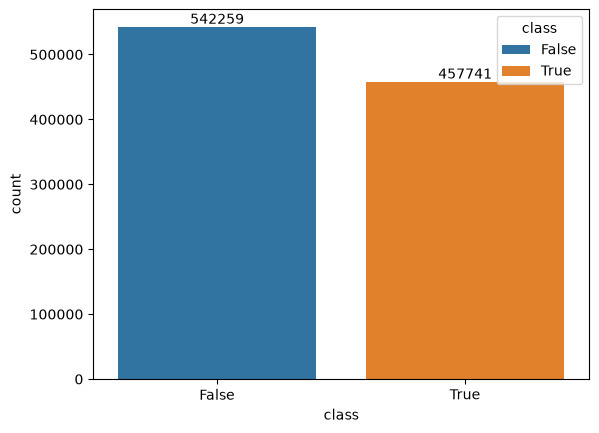

In [8]:
ax = sns.countplot(df, x="class", hue="class", order=sorted(df["class"].unique()))
for c in ax.containers:
    ax.bar_label(c)
plt.show()

In [11]:
sample = df.sample(n=100000, random_state=SEED)

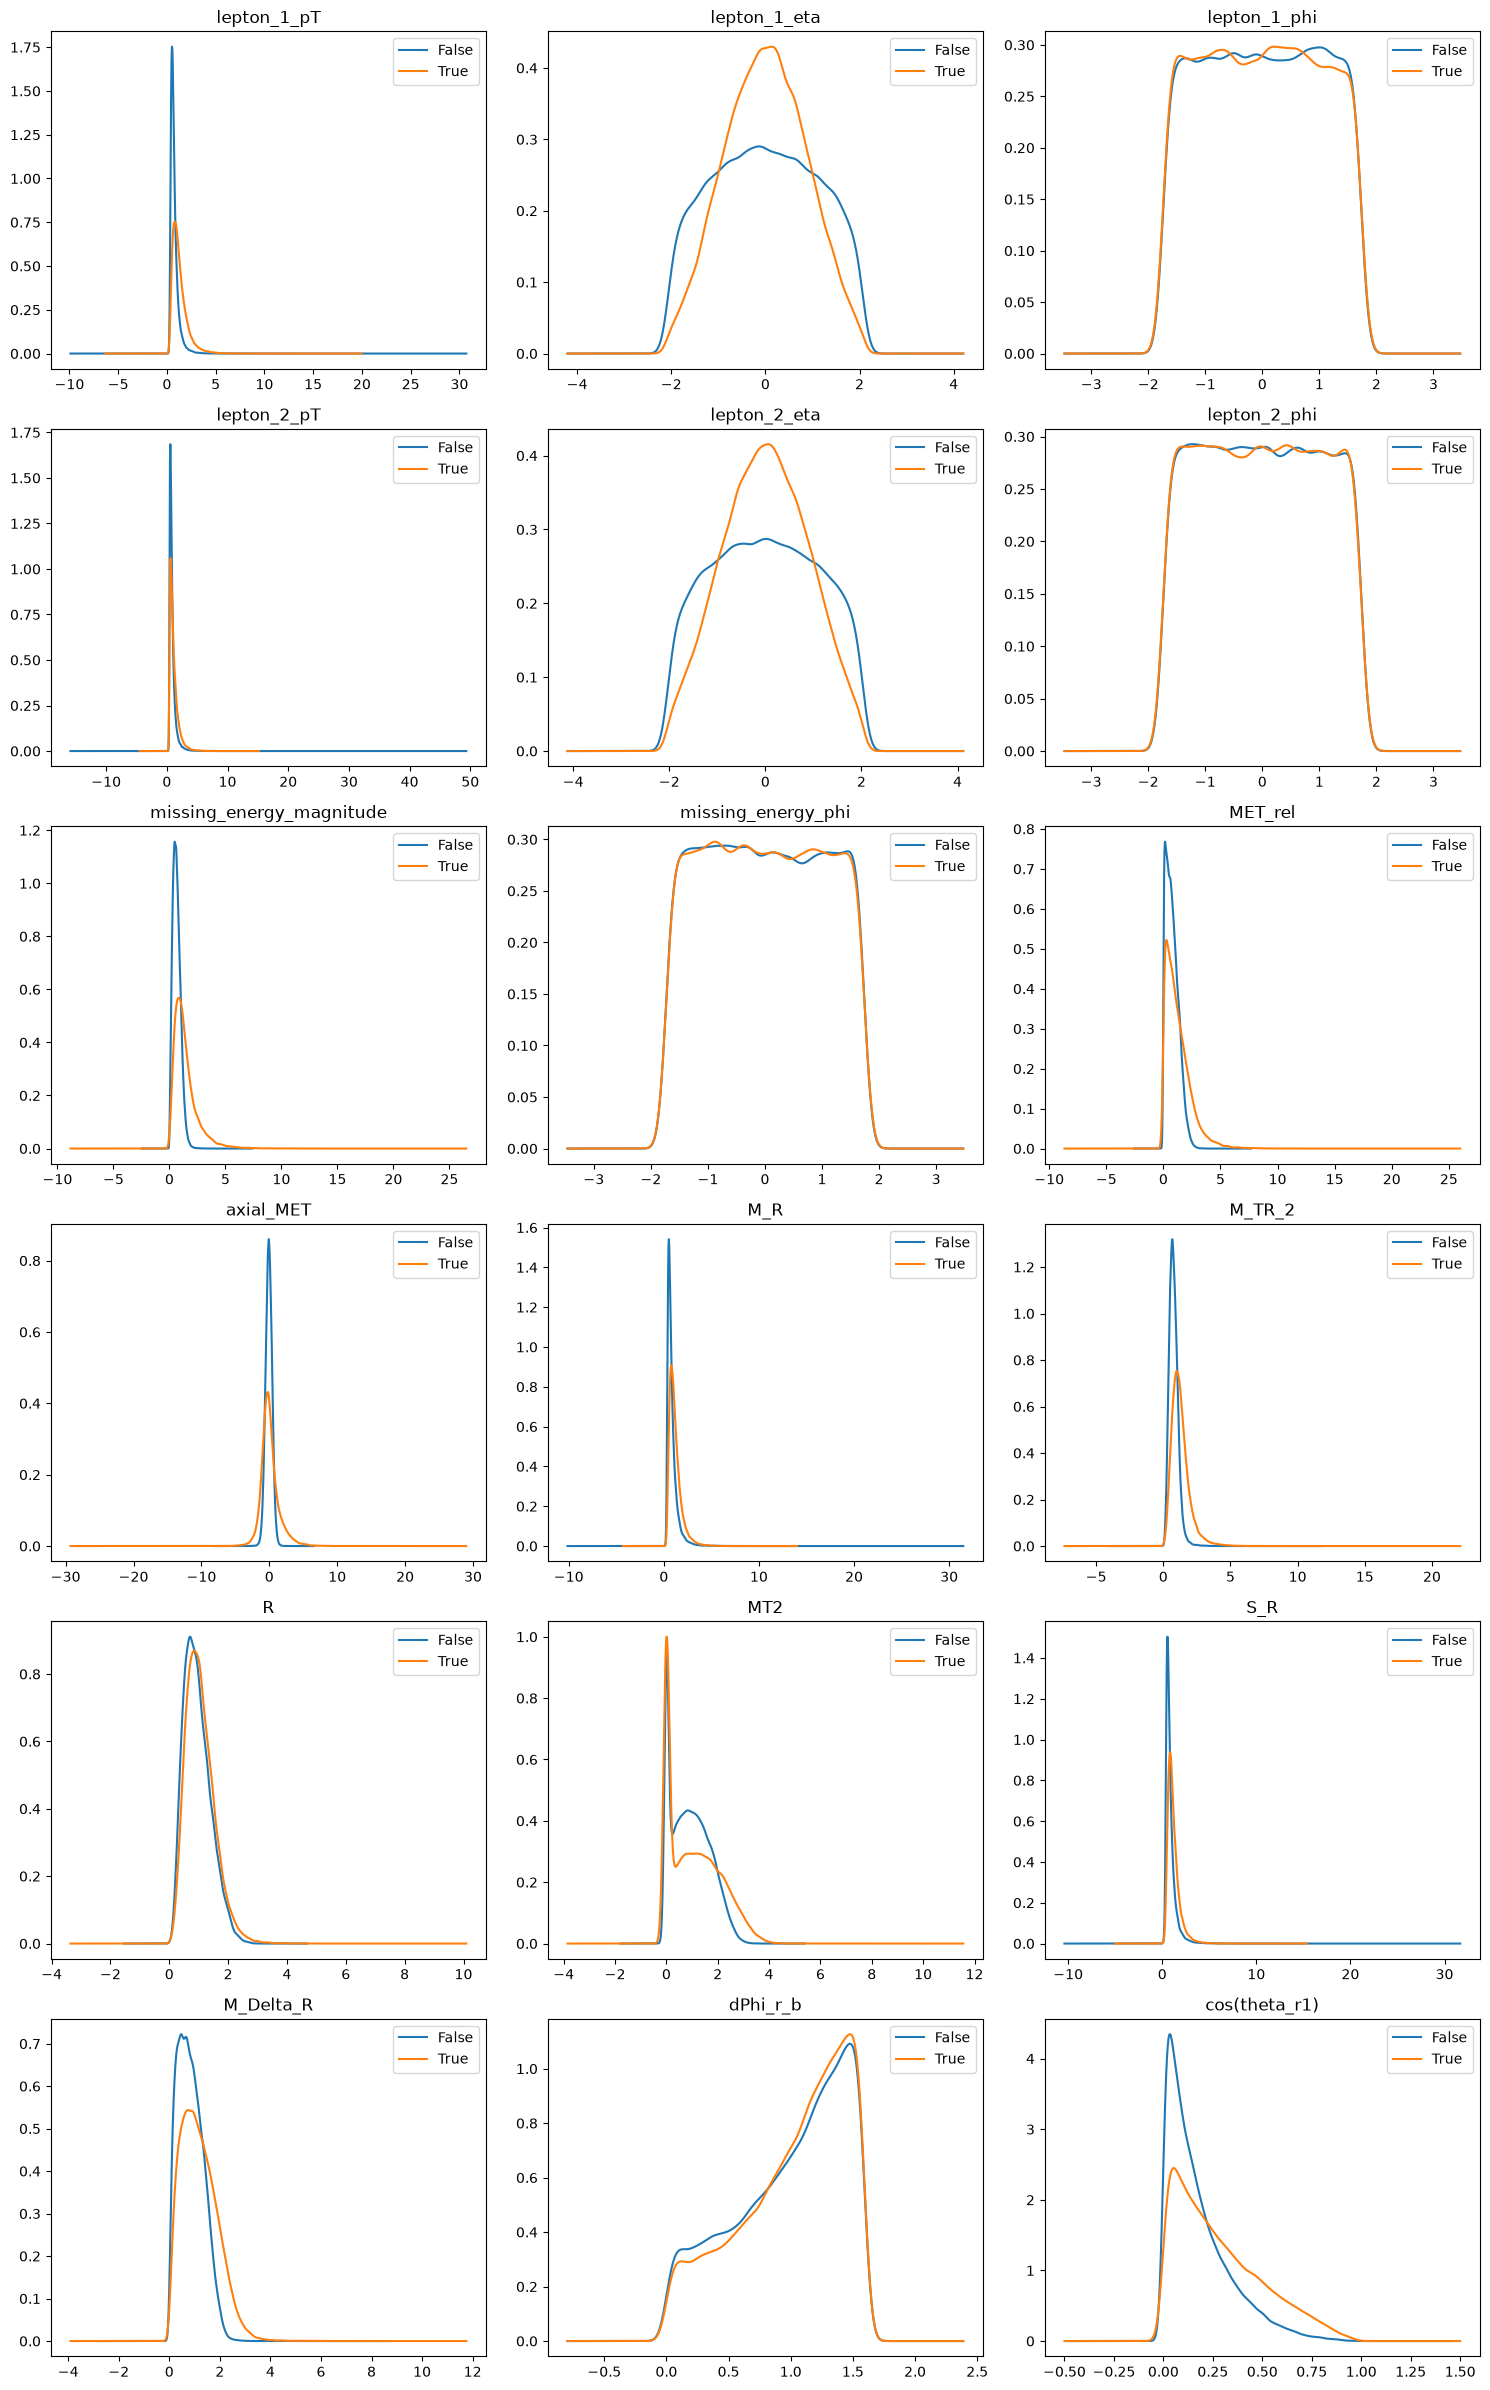

In [ ]:


float_cols = ["lepton_1_pT", "lepton_1_eta", "lepton_1_phi", "lepton_2_pT", "lepton_2_eta", "lepton_2_phi", "missing_energy_magnitude", "missing_energy_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos(theta_r1)"]
ncols = 3
nrows = 6

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, float_cols):
    sample.groupby("class")[col].plot(kind="kde", ax=ax, legend=True)
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(float_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

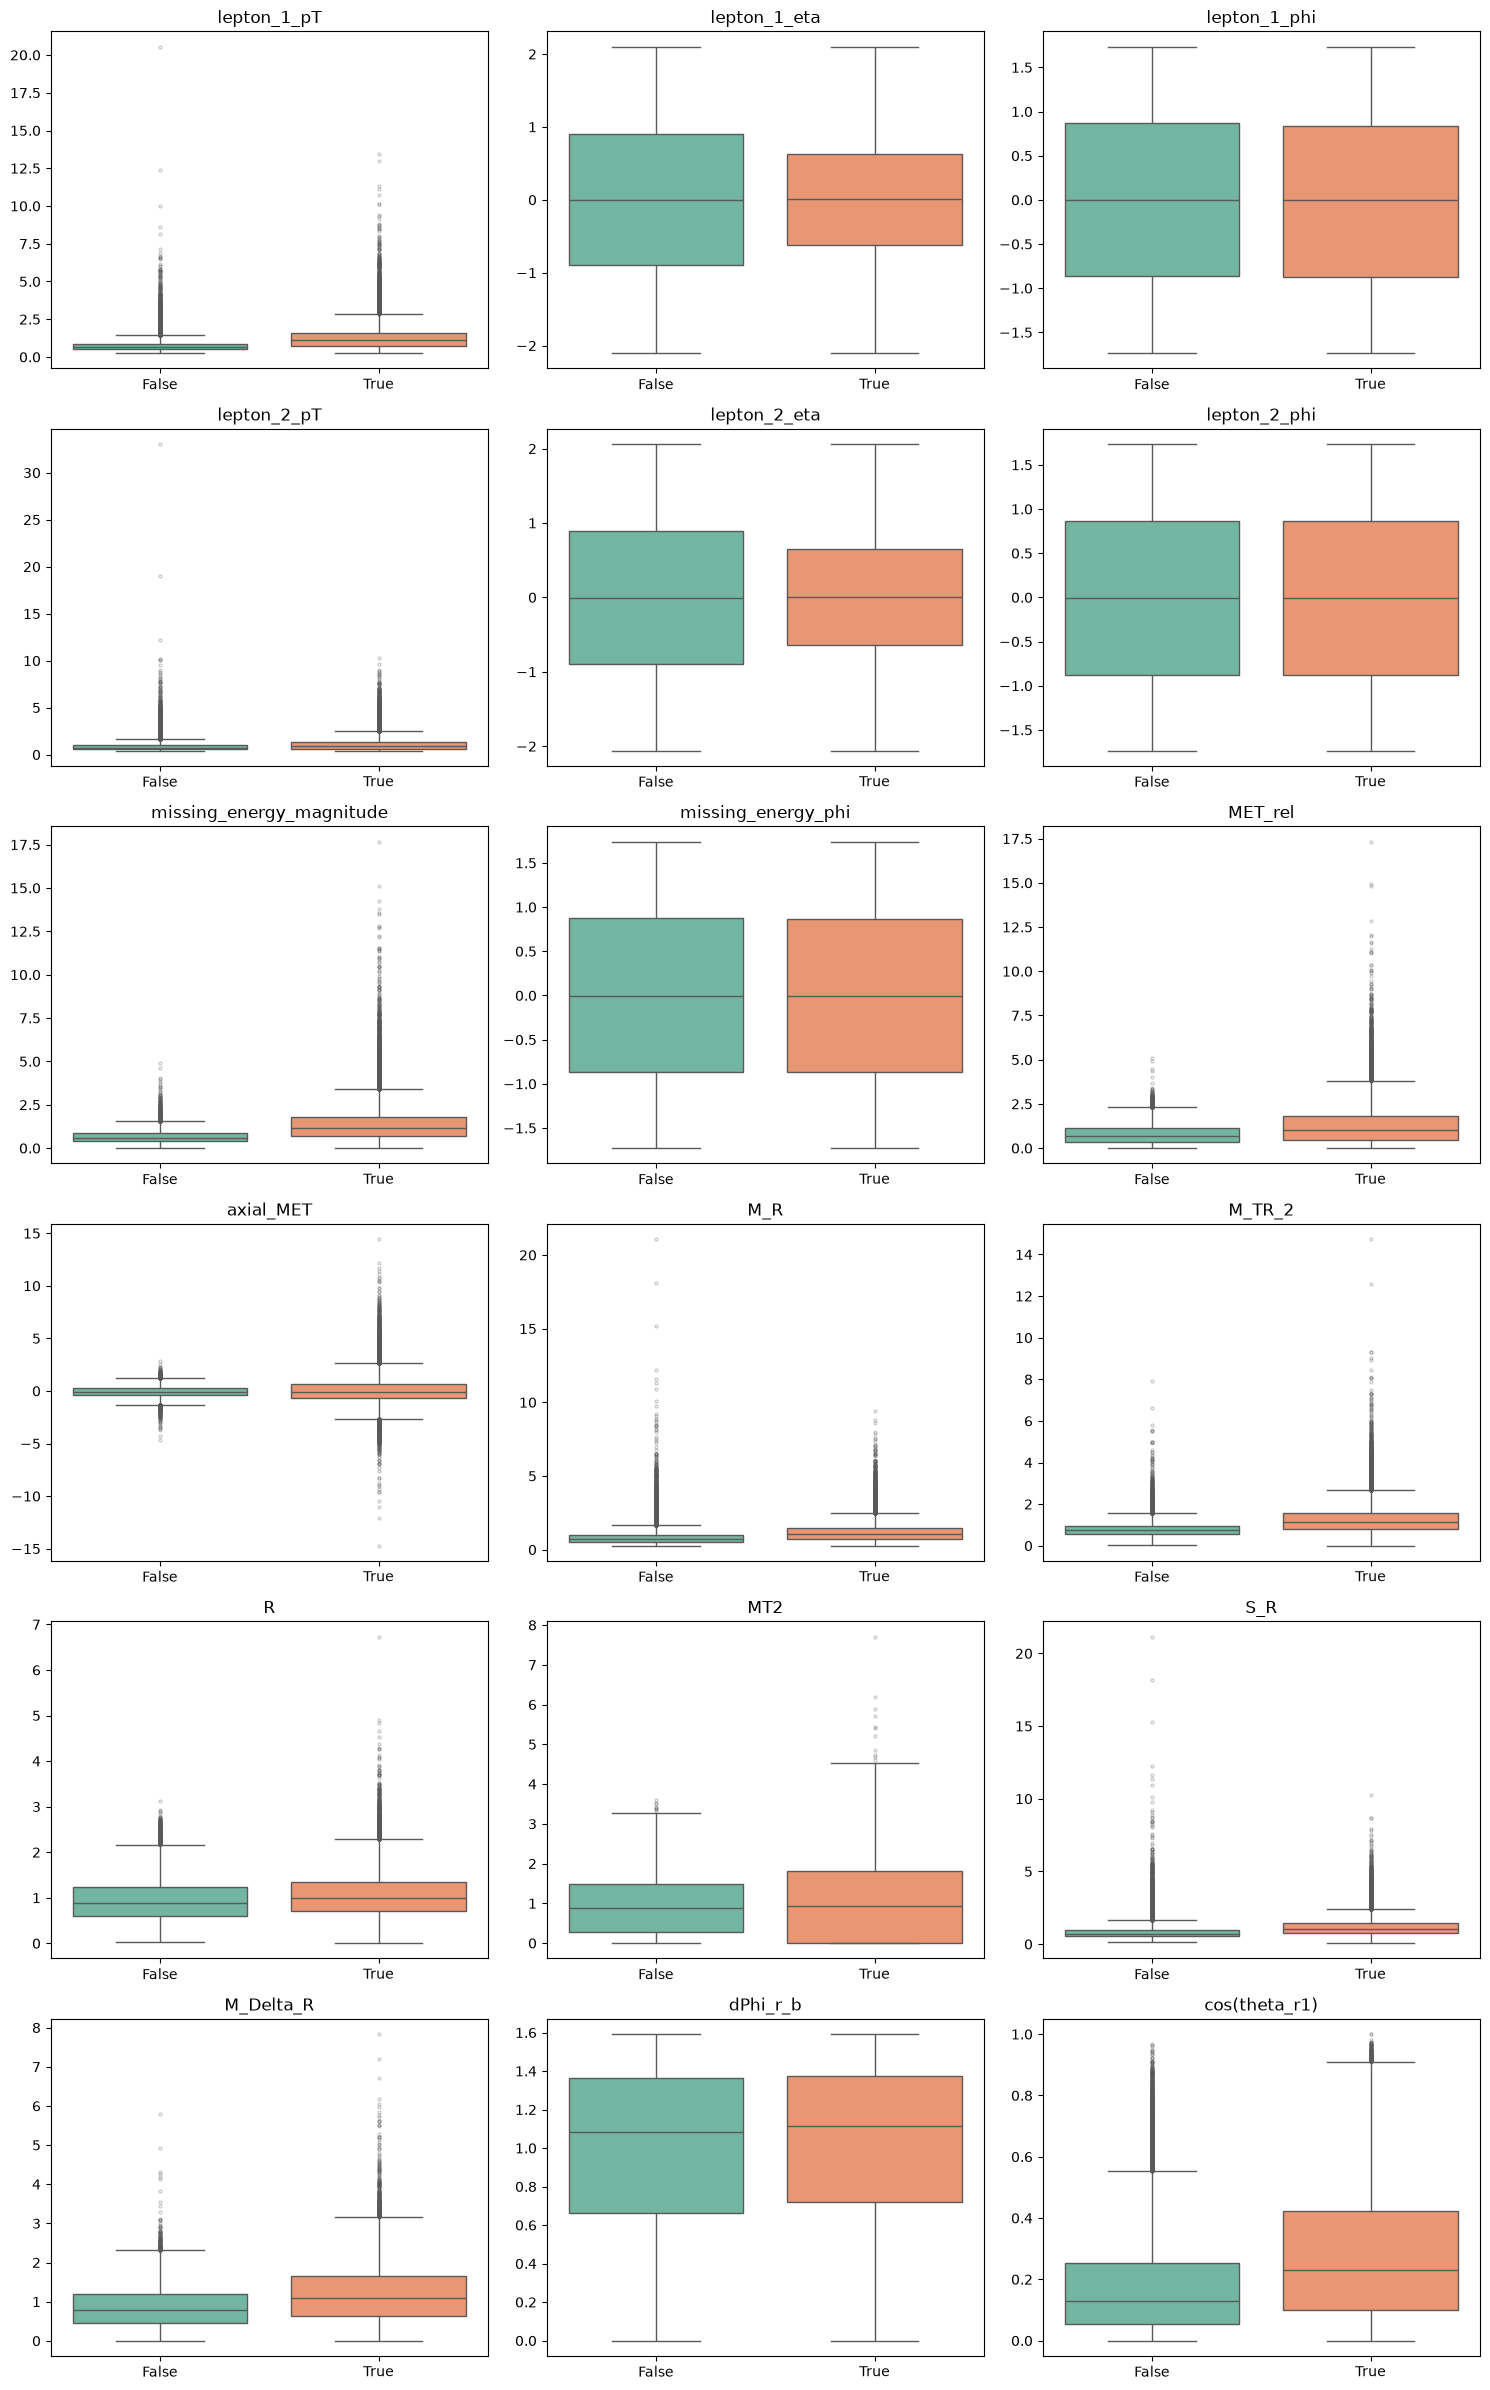

In [20]:
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, float_cols):
    sns.boxplot(data=sample, x="class", y=col, hue="class", palette="Set2",
                legend=False, ax=ax, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(float_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [22]:
g = sample.groupby("class")[float_cols]
stats_cls = pd.concat({"skośność": g.skew().T, "kurtoza": g.kurt().T}, axis=1).round(3)
stats_cls

skośność         kurtoza        
class                       False  True     False   True 
lepton_1_pT                 5.375  2.416  103.912  11.876
lepton_1_eta                0.005  0.001   -1.044  -0.546
lepton_1_phi               -0.009  0.009   -1.200  -1.187
lepton_2_pT                 7.873  2.662  251.426  11.976
lepton_2_eta                0.008 -0.008   -1.067  -0.619
lepton_2_phi                0.011  0.006   -1.201  -1.204
missing_energy_magnitude    0.979  2.477    2.862  11.896
missing_energy_phi          0.016  0.011   -1.205  -1.201
MET_rel                     0.756  1.936    0.285   7.740
axial_MET                  -0.117  1.030    1.076   5.557
M_R                         5.367  2.224   82.044   9.103
M_TR_2                      1.988  2.180   15.685  12.908
R                           0.653  0.958    0.132   2.089
MT2                         0.381  0.577   -0.796  -0.597
S_R                         5.390  2.238   83.148   9.496
M_Delta_R                   0.525  0.776    0.049   1.133
dPhi_r_b                   -0.549 -0.645   -0.822  -0.625
cos(theta_r1)               1.376  0.795    1.815  -0.187